In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/clean/crop_yield_clean.csv")
sns.set_theme(style="whitegrid")
df.shape

(648, 4)

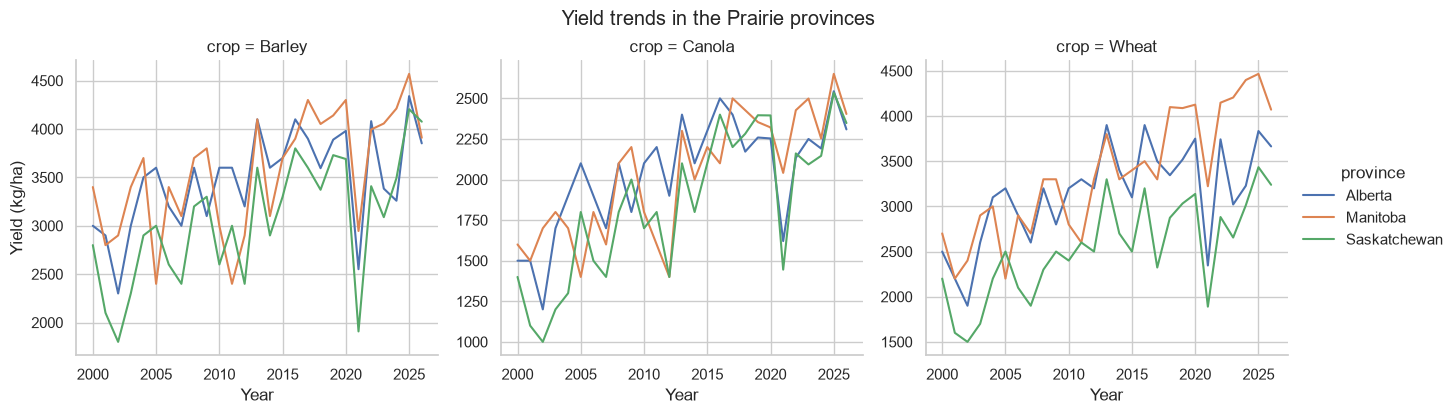

In [7]:
prairies = df[df["province"].isin(["Alberta", "Saskatchewan", "Manitoba"])]
g = sns.relplot(
    data=prairies, x="year", y="yield_kg_ha", hue="province",
    col="crop", kind="line", height=4, aspect=1.1,
    facet_kws={"sharey": False},
)
g.set_axis_labels("Year", "Yield (kg/ha)")
g.figure.suptitle("Yield trends in the Prairie provinces", y=1.03)
plt.savefig("../images/prairie_trends.png", dpi=150, bbox_inches="tight")
plt.show()

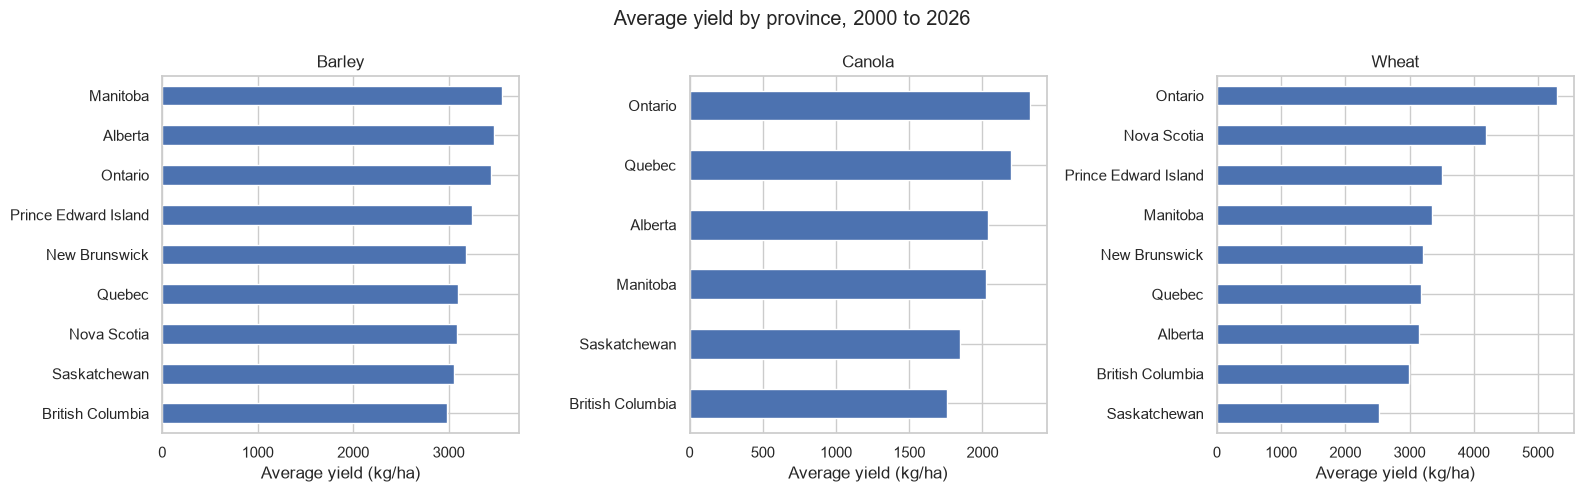

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, crop in zip(axes, ["Barley", "Canola", "Wheat"]):
    rank = (df[df["crop"] == crop].groupby("province")["yield_kg_ha"]
            .mean().sort_values())
    rank.plot(kind="barh", ax=ax, title=f"{crop}")
    ax.set_xlabel("Average yield (kg/ha)")
    ax.set_ylabel("")
plt.suptitle("Average yield by province, 2000 to 2026")
plt.tight_layout()
plt.savefig("../images/province_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

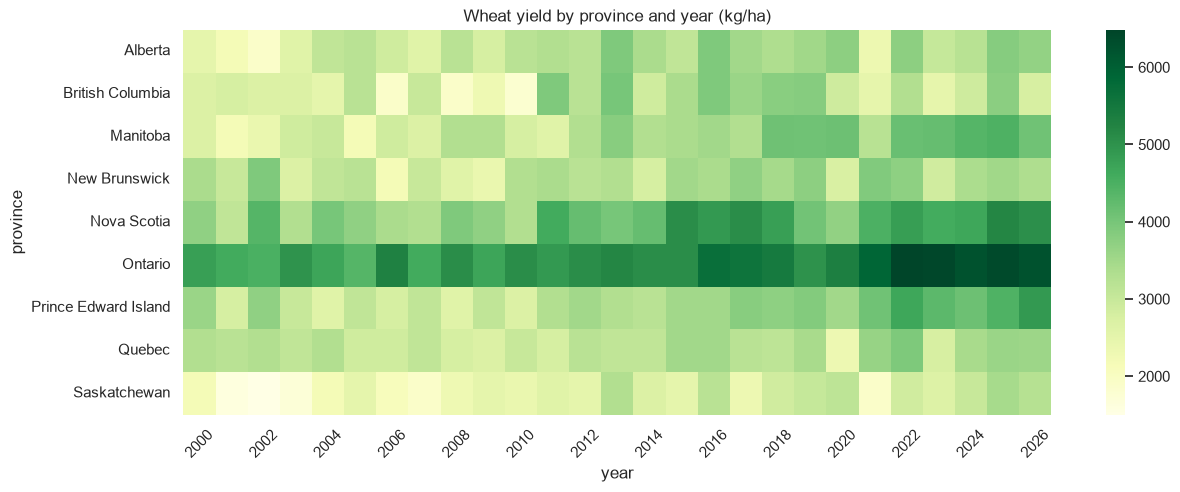

In [6]:
crop = "Wheat"
pivot = df[df["crop"] == crop].pivot_table(
    index="province", columns="year", values="yield_kg_ha")
plt.figure(figsize=(14, 5))
sns.heatmap(pivot, cmap="YlGn", xticklabels=2)
plt.xticks(rotation=45)
plt.title(f"{crop} yield by province and year (kg/ha)")
plt.savefig("../images/heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

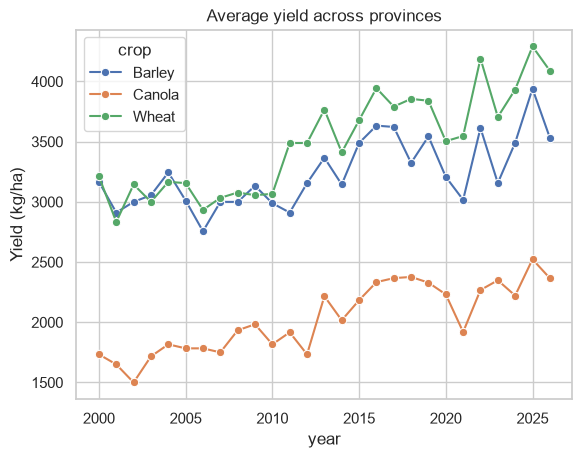

In [5]:
yearly = df.groupby(["crop", "year"])["yield_kg_ha"].mean().reset_index()
sns.lineplot(data=yearly, x="year", y="yield_kg_ha", hue="crop", marker="o")
plt.title("Average yield across provinces")
plt.ylabel("Yield (kg/ha)")
plt.savefig("../images/average_trend.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
yearly = df.groupby(["crop", "year"])["yield_kg_ha"].mean().reset_index()

early = yearly[yearly["year"].between(2000, 2004)].groupby("crop")["yield_kg_ha"].mean()
recent = yearly[yearly["year"].between(2021, 2025)].groupby("crop")["yield_kg_ha"].mean()
print("% change, 2000-2004 average vs 2021-2025 average:")
print(((recent - early) / early * 100).round(1))

y = yearly.pivot(index="year", columns="crop", values="yield_kg_ha")
print("\n% change in 2021 vs 2020:")
print((y.pct_change() * 100).loc[[2021]].round(1))

% change, 2000-2004 average vs 2021-2025 average:
crop
Barley    12.0
Canola    34.0
Wheat     28.1
Name: yield_kg_ha, dtype: float64

% change in 2021 vs 2020:
crop  Barley  Canola  Wheat
year                       
2021    -5.9   -14.0    1.2
